# Cancer Classification Model Report

---
embed-resources: true
echo: false
---

## Introduction

The purpose of this report is to present the development of a model that serves as a "universal" cancer detection and classification model, given gene expression data collected vias next-generation sequencing such as RNA-Seq. 

The primary goal is to create a potential framework that can accomodate for constantly evolving sets of technologies that can measure gene expression. This framework can then potentially be used as a part of the process in detecting and identifying cancers.

## Methods

In [11]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

<u>**These are imports for accessing the pandas library and for visualizations:**</u>
```
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
```

<u>**These imports are related to model building and scoring:**</u>
```

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
```

<u>**These imports were used for model preprocessing:**</u>
```

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
```

### Data

The underlying source of this data is the The Cancer Genome Atlas Pan-Cancer Analysis Project. The data was accessed via synapse.org. The specific data for this model was collected and modified based on a submission to the UCI Irvine Machine Learning Repository.

- https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq

<u>**Data Dictionary for reference**</u>

##### Response

**`cancer`**

- `[object]` the clinically determined cancer type, one of:
    - `BRCA`: Breast Invasive Carcinoma
    - `PRAD`: Prostate Adenocarcinoma
    - `KIRC`: Kidney Renal Clear Cell Carcinoma
    - `LUAD`: Lung Adenocarcinoma
    - `COAD`: Colon Adenocarcinoma

##### Features

**`gene_####`**

- `[float64]` gene expression (for gene number `####` in the dataset) quantification as measured by an [Illumina HiSeq](https://www.illumina.com/content/dam/illumina-support/documents//products/datasheets/datasheet_hiseq_systems.pdf) platform


In [4]:
genetics = pd.read_parquet("https://lab.cs307.org/genetics/data/genetics.parquet")

<u>**First few rows of the data**</u>

In [5]:
genetics.head(5)

,cancer,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,...,gene_3990,gene_3991,gene_3992,gene_3993,gene_3994,gene_3995,gene_3996,gene_3997,gene_3998,gene_3999
0,PRAD,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,...,0.000000,11.722884,11.831470,7.785282,11.877556,4.926711,0.591871,8.294230,9.086553,6.475515
1,LUAD,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,...,0.000000,10.406705,10.795447,8.007330,11.330637,5.041931,1.327170,6.344054,9.532814,4.216191
2,PRAD,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,...,0.000000,11.033850,10.292609,6.580491,11.152196,0.000000,0.000000,4.575712,10.485900,4.499029
3,PRAD,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,...,0.000000,11.137958,10.401871,6.259530,11.640385,3.068258,0.000000,5.421661,9.660732,6.612882
4,BRCA,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,...,0.360982,10.757932,9.944203,8.311430,11.275572,1.580097,0.000000,6.935271,10.425698,5.104899


<u>**General summary statistics of data**</u>

In [6]:
genetics.describe().transpose().rename(columns = {'25%' : '25th percentile', '50%' : '50th percentile', '75%' : '75th percentile'})

,count,mean,std,min,25th percentile,50th percentile,75th percentile,max
gene_0,801.0,0.026642,0.136850,0.000000,0.000000,0.000000,0.000000,1.482332
gene_1,801.0,3.010909,1.200828,0.000000,2.299039,3.143687,3.883484,6.237034
gene_2,801.0,3.095350,1.065601,0.000000,2.390365,3.127006,3.802534,6.063484
gene_3,801.0,6.722305,0.638819,5.009284,6.303346,6.655893,7.038447,10.129528
gene_4,801.0,9.813612,0.506537,8.435999,9.464466,9.791599,10.142324,11.355621
...,...,...,...,...,...,...,...,...
gene_3995,801.0,4.433993,2.007452,0.000000,3.092157,4.387211,5.725212,11.574338
gene_3996,801.0,1.678233,1.470913,0.000000,0.556895,1.366420,2.574320,8.123625
gene_3997,801.0,7.218995,1.122035,3.310791,6.512440,7.277390,8.034546,10.227917
gene_3998,801.0,9.513649,0.570016,7.599534,9.145107,9.480013,9.866715,11.193827


<u>**Various Visualizations of the Data**</u>

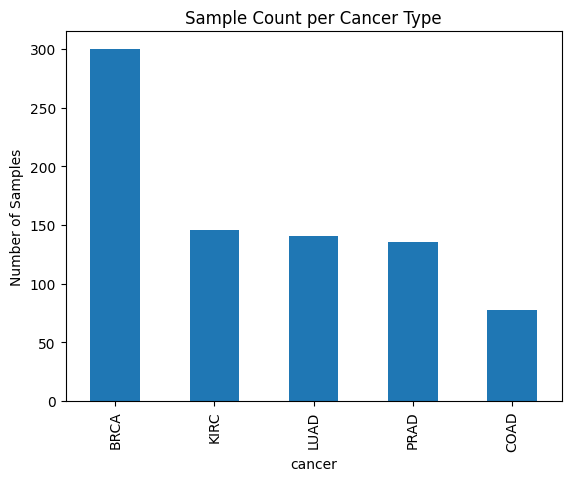

In [ ]:
genetics["cancer"].value_counts().plot(kind = "bar")
plt.ylabel("Number of Samples")
plt.title("Sample Count per Cancer Type")
plt.show()

Figure 1. Distribution of samples across cancer types in the genetics dataset. BRCA has the largest number of samples, while COAD has the fewest. Overall, class counts are moderately imbalanced but sufficient for multiclass classification.

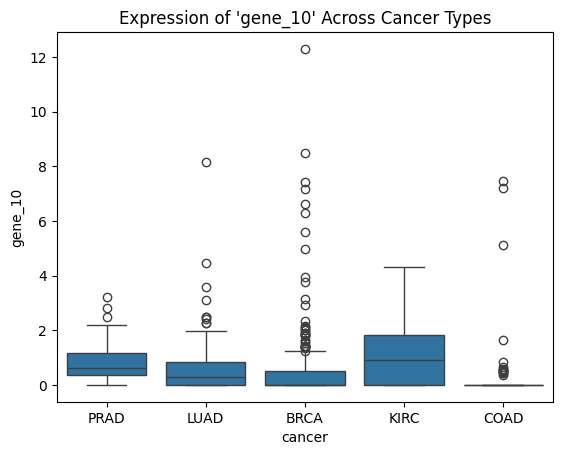

In [10]:
sns.boxplot(x = "cancer", y = "gene_10", data = genetics)
plt.title("Expression of 'gene_10' Across Cancer Types")
plt.show()

Figure 2. Distribution of expression levels for gene_10 across cancer types. Differences in median and variability are observed between cancers, with some classes showing unique expression patterns and outliers, indicating that individual genes may contribute discriminative signal for cancer classification.

### Models

To prepare for model development, the data was first split into training and testing sets for both predictors (X) and the response variable (y). The feature matrix (X) includes only numerical values. 

For model preprocessing, a pipeline was defined using the `StandardScaler` transformer. The pipeline imputes missing values with the mean and standardizes the features. The pipeline was then combined with the numerical features using `ColumnTransformer`, ensuring all preprocessing steps are applied consistently across the dataset. The preprocessor was then fit and transformed on the training data prior to modeling.

```
X = genetics.drop(columns="cancer", axis = 1)
y = genetics["cancer"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
)

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
preprocessor = make_column_transformer((numeric_transformer, numeric_features))
```

In [12]:
X = genetics.drop(columns="cancer", axis = 1)
y = genetics["cancer"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
)

numeric_transformer = make_pipeline(SimpleImputer(strategy = 'mean'), StandardScaler())
numeric_features = X_train.select_dtypes(include = ['int64', 'float64']).columns
preprocessor = make_column_transformer((numeric_transformer, numeric_features))

To model the cancer classifications, HistGradientBoostingClassifier was chosen as the base classifier for its performance and stability. The model was then made using `make_pipeline` and fit to the training data. 

In [13]:
model = make_pipeline(preprocessor, HistGradientBoostingClassifier())
model.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('pipeline', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Results

The models performance was graded using `accuracy_score` and was also evaluated using `confusion-matrix` and `cross_val_score`.

In [ ]:
cv_scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")

In [ ]:
print("Accuracy score of model: ", accuracy_score(y_test, model.predict(X_test)), '\n'
      "Confusion Matrix of model: ", '\n', confusion_matrix(y_test, model.predict(X_test)), '\n'
      "Cross Validation scores of matrix: ", cv_scores, '\n'
      , "Mean Cross Validation score: ", cv_scores.mean())


Accuracy score of model:  1.0 
Confusion Matrix of model:  
 [[61  0  0  0  0]
 [ 0 17  0  0  0]
 [ 0  0 25  0  0]
 [ 0  0  0 29  0]
 [ 0  0  0  0 29]] 
Cross Validation scores of matrix:  [0.99378882 1.         1.         0.99375    1.        ] 
 Mean Cross Validation score:  0.9975077639751554


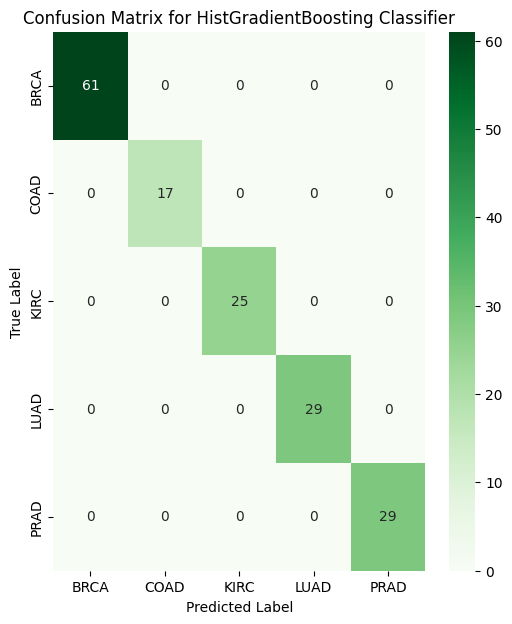

In [21]:
plt.figure(figsize = (6, 7))
sns.heatmap(
    confusion_matrix(y_test, model.predict(X_test)),
    annot = True,
    fmt = "d",
    cmap = "Greens",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix for HistGradientBoosting Classifier")
plt.show()

Figure 3. Confusion matrix for the HistGradientBoosting classifier on the held-out test set. All samples are correctly classified, with no misclassifications across cancer types, indicating perfect test accuracy and strong class separability within the dataset.

## Discussion

### Would I deploy this model? 
I would NOT deploy this model at this point in time. Although the HistGradientBoosting classifier achieved near-perfect performance on the held-out test set and during cross-validation, these results are based entirely on data originating from a single source and sequencing platform. As a result, the model’s real world generalizability   cannot be confidently established.

### Risks avoided by not using this model:
- Overconfidence due to limited validation: The model has only been evaluated on randomly split data from the same dataset. Performance may degrade significantly when applied to samples from different hospitals, populations, or sequencing technologies.
- Lack of clinical interpretability: While the model performs well, the gradient boosting approach does not provide straightforward biological explanations for its predictions, which is critical in clinical decision-making contexts.

### Potential improvements
- External validation: Evaluate the model on independent gene expression datasets collected from different institutions or platforms to assess real-world generalization.
- Expanded evaluation metrics: Incorporate metrics beyond accuracy, such as calibration curves or uncertainty estimates, to better assess prediction confidence.

## Conclusion

Overall, this model shows promising results, but is not close to being ready for real-world implementation. The model demonstrates a very strong relationship between gene and cancer classification, but with external factors that might have inflated the results, the model needs to be externally validated to be safely implemented further. 

Moving further, by using a wider variety of data and maybe tuning hyperparameters, as well as testing alternative model architectures for cross referencing, an ideal model for cancer classification can come into fruition. 